<a href="https://colab.research.google.com/github/jihyeon26/computational-language-technology-hs26/blob/main/stage2/work_packages/stage2_wp2_finetuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 2. Fine-Tuning Compact Open Models
Part 1 built classical representations trained from scratch on the corpus (Word2Vec, FastText, Doc2Vec). It also showed their limits on the open-models track: Word2Vec has no vector for unseen model names, FastText groups names by spelling rather than meaning, and Doc2Vec does not separate the open-models articles well from the rest of the corpus.

This part asks whether **pre-trained compact open models, adapted with parameter-efficient fine-tuning (QLoRA)**, represent the open-models articles better than the classical embeddings, and at what cost in model size, training time and GPU memory:
1. **Task definition**: a theme classification of the open-models articles
2. **Model selection**: compact open models that fit on a Colab GPU
3. **Baselines**: Doc2Vec (Part 1) and the frozen pre-trained model, each with a linear classifier
4. **QLoRA fine-tuning**: training setup, resource tracking and evaluation on the shared validation split
5. **Track analysis and handover**: unseen model names, theme trends, and article vectors, predictions and resource logs for the comparative evaluation (Part 3)

Only small low-rank adapters (LoRA) and the classification head are trained; the weights of the pre-trained model stay frozen and are loaded in 4-bit (QLoRA). This is **not full fine-tuning**: the share of trainable parameters is reported for every model.

**Key results** (shared validation split):
1. **Fine-tuning helps**: QLoRA reaches a macro-F1 of 0.80 (Qwen3-1.7B) and 0.84 (Qwen3-4B), 5 to 9 points above Doc2Vec and the frozen models (Sections 2.6.2 – 2.6.3).
2. **The smaller model is enough**: Qwen3-4B is not significantly better than Qwen3-1.7B, which trains 2.3× faster with 1.7× less GPU memory (Sections 2.3, 2.9).
3. **The first 512 tokens are enough**: reading the whole article does not improve the fine-tuned models (Section 2.6.4).
4. **Unseen model names are placed by their spelling**, not by their context (Section 2.8.1).
5. **Track trend**: among the articles that mention open models, the share about developer tools grows from about a quarter to about a half (Section 2.8.2).

**Labels**: the themes were first taken from the Stage 1 topics (**topic labels**). A hand check found only 64% of them correct, so all articles were labelled again with a written rubric (**reviewed labels**, Sections 2.2.2 – 2.2.3). Unless stated otherwise, the models are trained and evaluated on the reviewed labels; the first run on the topic labels is kept as a comparison (Section 2.6.5).

**Cache**: every long step saves its result on Google Drive and loads it when the notebook is run again.

| Team member | Sections | Contribution |
|---|---|---|
| Jihyeon Choung | 2.1 – 2.8 | selection and QLoRA fine-tuning of compact open models, training setup and resource documentation |

## 2.1 Setup
A GPU runtime is required. Start with the main model only (`MODELS`) for a first full run.

Inputs:
- `corpus_clean.parquet` and `open_models_core.parquet`: the cleaned corpus and the 1,210 core articles with their Stage 1 topic
- `artifacts/stage2_wp1/splits.parquet`: the training / validation split shared by all Stage 2 work packages
- `doc_vectors.parquet` (Part 1, Google Drive): the Doc2Vec vector of every article, used as the classical baseline

In [ ]:
!pip install -q -U transformers peft bitsandbytes accelerate datasets gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 155.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 59.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 64.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 51.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 99.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 50.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [ ]:
from pathlib import Path

# Clone the project repository
REPO = Path("/content/computational-language-technology-hs26")
if REPO.exists():
    !git -C {REPO} pull -q
else:
    !git clone -q https://github.com/jihyeon26/computational-language-technology-hs26.git {REPO}

# Mount Google Drive (input data and outputs)
from google.colab import drive
drive.mount("/content/drive")

# Inputs: Stage 1 outputs and Part 1 (WP1) outputs
DATA_DIR = Path("/content/drive/MyDrive/HSLU/CLT/data/processed")
WP1_DIR = Path("/content/drive/MyDrive/HSLU/CLT/extraction_outputs/stage2/wp1")

# Labels used for training: "checked" (reviewed labels, Section 2.2.3) or "silver" (topic labels, first run)
TRAIN_LABELS = "checked"
LABELS_FILE = REPO / "artifacts/stage2_wp2/labels_checked.csv"

# Outputs of this notebook (also used as cache). The outputs that do not depend on the labels (frozen-model embeddings,
# Doc2Vec) are shared in OUT_DIR; the outputs that do (adapters, predictions, results) go to RUN_DIR, one per label version
OUT_DIR = Path("/content/drive/MyDrive/HSLU/CLT/extraction_outputs/stage2/wp2")
RUN_DIR = OUT_DIR if TRAIN_LABELS == "silver" else OUT_DIR / TRAIN_LABELS
FIG = RUN_DIR / "figures"
ADAPTERS = RUN_DIR / "adapters"
for d in (FIG, ADAPTERS):
    d.mkdir(parents=True, exist_ok=True)

# Trainer checkpoints stay on the local disk (only the final adapter is copied to Drive)
CKPT_DIR = Path("/content/wp2_runs")

Mounted at /content/drive


In [ ]:
# Libraries
import gc, json, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Fix the seed (same as Part 1)
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Cosine
def unit(X):
    return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-9)

# Save figure and show it
def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# Release GPU memory between models
def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none"
# Native bf16 needs an Ampere GPU or newer (L4, A100); is_bf16_supported() is also True on a T4, where bf16 is emulated and slow
BF16 = torch.cuda.is_available() and torch.cuda.get_device_capability()[0] >= 8
print(f"GPU: {GPU} | bf16: {BF16}")

GPU: NVIDIA L4 | bf16: True


In [ ]:
# Stage 1 outputs (API reference pages left out, as in Part 1)
corpus = pd.read_parquet(DATA_DIR / "corpus_clean.parquet",
                         columns=["doc_id", "quarter", "text", "om_tier", "is_api_reference"])
corpus = corpus[~corpus["is_api_reference"]].drop(columns="is_api_reference").reset_index(drop=True)
core = pd.read_parquet(DATA_DIR / "open_models_core.parquet", columns=["doc_id", "title", "dominant_topic_label"])

# Shared split of Part 1
splits = pd.read_parquet(REPO / "artifacts/stage2_wp1/splits.parquet")
corpus["split"] = corpus["doc_id"].map(dict(zip(splits["doc_id"], splits["split"])))
print(f"{len(corpus):,} articles")
display(pd.crosstab(corpus["om_tier"], corpus["split"], margins=True))

45,462 articles


split,train,validation,All
om_tier,,,
core,968,242,1210
mention,2262,565,2827
none,33139,8286,41425
All,36369,9093,45462


## 2.2 Task Definition: Theme Classification of Open-Models Articles
The extrinsic task must be relevant to the open-models track and must have labels for training and evaluation. The relevance tier (`om_tier`) is not used as a label: it was defined by the keywords of the WP1 lexicon, so a classifier would only learn to find these keywords again.

Instead, the 1,210 core articles are classified into **5 themes** of the open-models discourse. The themes group the 16 Stage 1 topics: several topics are small (T09 and T15: 26 articles each) and some are close in meaning (T02 DeepSeek and T07 China–US). **T16** (*people · ask · find*) is left out: it had the weakest coherence of the Stage 1 topics (NPMI 0.10) and gathers general writing without a clear theme. An article belongs to the theme of its **main subject**, not to every theme it mentions:

| Theme | Main subject | Stage 1 topics |
|---|---|---|
| `model_families` | a specific model or model family of any vendor: release, versions, benchmarks, capabilities, licence | T08 Nemotron · T09 Gemma · T11 multilingual / instruction · T13 Meta / Llama · T15 Qwen |
| `china_geopolitics` | China–US competition, export controls, AI policy and regulation, national AI race | T02 DeepSeek / R1 · T07 China / United States |
| `research_techniques` | methods: training, architecture and efficiency, multimodal techniques, safety research | T01 reasoning / RL · T05 memory / attention · T06 image / video |
| `developer_tools` | using models: agents, coding tools, APIs, platforms, tutorials, deployment | T04 Claude / agents / coding · T10 API / Python |
| `business_compute` | hardware and infrastructure, investment, enterprise adoption, markets | T03 Blackwell / GPU · T12 stock / investors · T14 enterprise / innovation |

The labels are built in two steps: the Stage 1 topic of an article gives a first label (**topic label**, this section); after a hand check (Section 2.2.2), all articles are labelled again with the rubric above (**reviewed label**, Section 2.2.3).

In [ ]:
# Stage 1 topic -> theme
THEMES = {
    "model_families":      ["T08", "T09", "T11", "T13", "T15"],
    "china_geopolitics":   ["T02", "T07"],
    "research_techniques": ["T01", "T05", "T06"],
    "developer_tools":     ["T04", "T10"],
    "business_compute":    ["T03", "T12", "T14"],
}
TOPIC_TO_THEME = {t: theme for theme, topics in THEMES.items() for t in topics}
LABELS = list(THEMES)
LABEL_ID = {label: i for i, label in enumerate(LABELS)}

task = core.merge(corpus[["doc_id", "quarter", "text", "split"]], on="doc_id")
task["topic"] = task["dominant_topic_label"].str[:3]
task["theme"] = task["topic"].map(TOPIC_TO_THEME)
print(f"Left out (T16): {task['theme'].isna().sum()} articles")
task = task.dropna(subset=["theme"]).reset_index(drop=True)

Left out (T16): 150 articles


### 2.2.1 Training, development and validation sets
The shared split of Part 1 is kept, so that the classical and the fine-tuned models are evaluated on the same articles:
- **validation** (Part 1): held-out evaluation set for every model of Stage 2. It is never used for training or model selection. The Doc2Vec vectors of these articles were also inferred, not trained, in Part 1.
- **train** (Part 1): split again into **train** (90%) and **dev** (10%, stratified by topic label). The dev set is used for model selection during fine-tuning (best epoch).

The sets are fixed here and are the same for both label versions.

In [ ]:
fit_ids, dev_ids = train_test_split(task.loc[task["split"] == "train", "doc_id"], test_size=0.1, random_state=SEED,
                                    stratify=task.loc[task["split"] == "train", "theme"])
task["set"] = np.select([task["doc_id"].isin(set(fit_ids)), task["doc_id"].isin(set(dev_ids))],
                        ["train", "dev"], "validation")

display(pd.crosstab(task["theme"], task["set"], margins=True)[["train", "dev", "validation", "All"]])

set,train,dev,validation,All
theme,,,,
business_compute,172,19,40,231
china_geopolitics,134,15,35,184
developer_tools,167,18,47,232
model_families,159,18,50,227
research_techniques,131,15,40,186
All,763,85,212,1060


### 2.2.2 Topic labels: hand check
The topic label is the theme of the dominant Stage 1 topic of an article. It is cheap, but a topic model is not an annotator: an article can mix several themes, and its dominant topic can be wrong. A stratified sample of validation articles (20 per theme) was therefore checked by hand with the rubric of Section 2.2, reading the title and the first 600 characters: `label_ok` says whether the topic label is correct and, if not, `correct_theme` gives the correct theme (`none` if no theme fits). If two themes weighed the same and the topic label was one of them, it counted as correct.

Only **64%** of the topic labels are correct. Many errors are model releases outside the five families of the Stage 1 topics (e.g. MiniMax, Kimi, Phi), which the topic model placed in other themes. These labels are too noisy to train and evaluate the models, so all articles were labelled again (Section 2.2.3).

In [ ]:
CHECK_PATH = OUT_DIR / "label_check_validation.csv"
if not CHECK_PATH.exists():
    sample = task[task["set"] == "validation"].groupby("theme", group_keys=False).sample(n=20, random_state=SEED)
    sample = sample.assign(text=sample["text"].str[:600], label_ok="", correct_theme="")
    sample[["doc_id", "title", "theme", "text", "label_ok", "correct_theme"]].to_csv(CHECK_PATH, index=False)
    print("Sample written to", CHECK_PATH.name, "- fill in label_ok / correct_theme, then re-run this cell")
    check = pd.DataFrame()
else:
    check = pd.read_csv(CHECK_PATH)
    check = check[check["label_ok"].notna()]
    ok = check["label_ok"].astype(str).str.lower().isin(["1", "1.0", "true", "yes", "y"])
    check["checked_theme"] = check["theme"].where(ok, check["correct_theme"])
    print(f"Checked: {len(check)} | topic label correct: {ok.mean():.1%}\n")
    display(pd.crosstab(check["theme"], check["checked_theme"], margins=True)
              .rename_axis(index="topic label", columns="hand check"))

### 2.2.3 Reviewed labels
All 1,060 articles were labelled again with the rubric of Section 2.2 (`artifacts/stage2_wp2/labels_checked.csv`, rubric in `annotation_rubric.md`). The sets of Section 2.2.1 are not changed.

| set | how the label was made (`label_source`) | articles |
|---|---|---|
| train, dev | `ai`: an LLM (Claude Opus 5.5) with the rubric, reading the title and the first 6,000 characters, without seeing the topic label | 848 |
| validation | `human`: the hand check of Section 2.2.2 | 100 |
| validation | `human_after_ai`: LLM label checked by hand, for every article where the LLM disagreed with the topic label or was not highly confident | 68 |
| validation | `ai_agrees_silver_high`: LLM label and topic label agree, with high LLM confidence | 44 |

The agreement of the LLM with the hand check (below) shows how far the LLM training labels can be trusted. Articles labelled `none` stay in the data but are left out of training and evaluation (label −1). In the code, the topic labels are called `silver` and the reviewed labels `checked`; `TRAIN_LABELS` (Section 2.1) selects the labels used for training.

In [ ]:
from sklearn.metrics import cohen_kappa_score

task["silver_theme"] = task["theme"]
if LABELS_FILE.exists():
    checked_labels = pd.read_csv(LABELS_FILE)
    task = task.merge(checked_labels[["doc_id", "checked_theme", "label_source", "ai_theme"]], on="doc_id", how="left")
    hand = task[task["label_source"] == "human"]
    print(f"LLM vs hand check ({len(hand)} articles): agreement {(hand['ai_theme'] == hand['checked_theme']).mean():.1%}, "
          f"kappa {cohen_kappa_score(hand['checked_theme'], hand['ai_theme']):.2f} | "
          f"topic labels vs hand check: agreement {(hand['silver_theme'] == hand['checked_theme']).mean():.1%}, "
          f"kappa {cohen_kappa_score(hand['checked_theme'], hand['silver_theme']):.2f}")
    print(f"Topic label = reviewed label: {(task['silver_theme'] == task['checked_theme']).mean():.1%} of all articles\n")
    display(pd.crosstab(task["label_source"], task["set"], margins=True))
    display(pd.crosstab(task["silver_theme"], task["checked_theme"], margins=True)
              .rename_axis(index="topic label", columns="reviewed label"))
else:
    print("No reviewed labels: training and evaluation use the topic labels")
    task["checked_theme"] = task["silver_theme"]

to_label = lambda themes: themes.map(LABEL_ID).fillna(-1).astype(int)   # -1: none
task["theme"] = task[f"{TRAIN_LABELS}_theme"]        # training labels
task["label"] = to_label(task["theme"])
task["eval_label"] = to_label(task["checked_theme"])  # evaluation labels
task["silver_label"] = to_label(task["silver_theme"])
task.drop(columns="text").to_parquet(RUN_DIR / "task_labels.parquet", index=False)
print(f"Training labels: {TRAIN_LABELS} | left out as none: {(task.loc[task['set'] != 'validation', 'label'] < 0).sum()} (training), "
      f"{(task.loc[task['set'] == 'validation', 'eval_label'] < 0).sum()} (validation)")

### 2.2.4 Model input
The input of the language models is the **title followed by the article text, cut to the first `MAX_LEN` tokens**. The articles have 1,464 tokens on average (Part 1), so most of them are cut. The beginning of a news article (title and lead) usually states its subject, but themes that appear only later in the text are missed. The share of articles that are cut is reported in Section 2.6.4, which also tests whether the cut explains the scores.

In [ ]:
MAX_LEN = 512

def model_input(df):
    return (df["title"].fillna("") + "\n\n" + df["text"]).tolist()

sets = {name: task[task["set"] == name].reset_index(drop=True) for name in ["train", "dev", "validation"]}

## 2.3 Model Selection
The models are chosen among the compact open models suggested in the project brief, with two constraints: they fit with QLoRA on a 16 GB Colab GPU, and they are supported for sequence classification by `transformers`.

| Model | Parameters | Role |
|---|---|---|
| Qwen3-1.7B | 1.7 B | main model: fast to train, so several runs fit in one session |
| Qwen3-4B | 4.0 B | larger model of the same family: shows the effect of size alone |

Comparing two sizes of **the same family** isolates the effect of model size; the trade-off between size, performance, training time and GPU memory is analysed in Part 3.

**Final choice**: both sizes are kept in the comparison, and **Qwen3-1.7B is the recommended model**. On the hand-checked validation labels it scores as well as Qwen3-4B (Section 2.6.3), with 2.3× shorter training, 2.2× faster prediction and 1.7× less GPU memory (Section 2.9). Qwen3-4B scores higher only on the validation labels made with the LLM annotator, which is no evidence that it classifies the themes better.

In [ ]:
MODELS = {
    "qwen3-1.7b": "Qwen/Qwen3-1.7B",
    "qwen3-4b":   "Qwen/Qwen3-4B",     # needs an L4 or A100
}

## 2.4 Training Setup and Resource Documentation
Every long step (embedding extraction, fine-tuning, prediction) is measured with the same tracker: wall-clock time, peak GPU memory and the GPU used. The results are stored per model in `resources.json` for the trade-off comparison in Part 3.

In [ ]:
RES_PATH = RUN_DIR / "resources.json"
RESOURCES = json.loads(RES_PATH.read_text()) if RES_PATH.exists() else {}

class track:
    """Measure time and peak GPU memory of a step: with track("qwen3-1.7b", "finetune"): ..."""
    def __init__(self, model, step):
        self.model, self.step = model, step
    def __enter__(self):
        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()
        self.t0 = time.perf_counter()
        return self
    def __exit__(self, *exc):
        if exc[0] is not None:
            return False
        peak = torch.cuda.max_memory_allocated() / 2**30 if torch.cuda.is_available() else 0.0
        RESOURCES.setdefault(self.model, {})[self.step] = {
            "seconds": round(time.perf_counter() - self.t0, 1), "peak_vram_gb": round(peak, 2), "gpu": GPU}
        RES_PATH.write_text(json.dumps(RESOURCES, indent=2))
        print(f"[{self.model} · {self.step}] {RESOURCES[self.model][self.step]}")

In [ ]:
from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification, BitsAndBytesConfig

# 4-bit quantisation of the frozen weights (QLoRA)
BNB = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
                         bnb_4bit_compute_dtype=torch.bfloat16 if BF16 else torch.float16)

def load_tokenizer(repo):
    tok = AutoTokenizer.from_pretrained(repo)
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    return tok

def batches(texts, tok, batch_size):
    """Tokenised batches, longest texts first so that a batch holds texts of similar length (less padding).
    Yields the positions of the texts in the batch, then the batch."""
    order = np.argsort([-len(t) for t in texts], kind="stable")
    for i in range(0, len(order), batch_size):
        idx = order[i:i + batch_size]
        yield idx, tok([texts[j] for j in idx], truncation=True, max_length=MAX_LEN, padding=True,
                       return_tensors="pt").to("cuda")

def in_input_order(positions, parts):
    """Put the batch outputs back in the order of the input texts."""
    out = np.vstack(parts)
    out[np.concatenate(positions)] = out.copy()
    return out

@torch.no_grad()
def run(fn, batch_iter):
    """Apply fn to every batch and return one output row per input, in input order."""
    positions, parts = [], []
    for idx, batch in batch_iter:
        positions.append(idx)
        parts.append(fn(batch))
    return in_input_order(positions, parts)

## 2.5 Baselines
Two baselines show what fine-tuning adds:
1. **Doc2Vec + logistic regression**: the classical article vectors of Part 1
2. **Frozen pre-trained model + logistic regression**: the compact model without fine-tuning; the article vector is the mean of its last hidden states (mean pooling over the tokens)

Both use the same linear classifier, trained on train + dev (no model selection is needed) and evaluated on validation.

Every method is scored on the reviewed validation labels (`macro_f1`, main score, with a 95% bootstrap interval); `macro_f1_silver` is the score on the topic labels. With about 210 validation articles, the interval is about ±6 points wide.

In [ ]:
def linear_probe(X_fit, y_fit, X_eval):
    y_fit = np.asarray(y_fit)
    keep = y_fit >= 0   # articles labelled none are left out
    clf = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)
    clf.fit(unit(X_fit[keep]), y_fit[keep])
    return clf.predict(unit(X_eval))

RESULTS = []      # one row per method: validation scores
PREDICTIONS = {}  # method -> predicted labels on validation

def bootstrap_ci(y_true, y_pred, n=1000):
    """95% interval of the macro-F1 over n resamples of the validation articles."""
    idx = np.random.default_rng(SEED).integers(0, len(y_true), (n, len(y_true)))
    return np.percentile([f1_score(y_true[i], y_pred[i], average="macro") for i in idx], [2.5, 97.5])

def record(method, y_pred):
    y_pred = np.asarray(y_pred)
    y_true = sets["validation"]["eval_label"].to_numpy()
    keep = y_true >= 0
    low, high = bootstrap_ci(y_true[keep], y_pred[keep])
    RESULTS.append({"method": method, "accuracy": accuracy_score(y_true[keep], y_pred[keep]),
                    "macro_f1": f1_score(y_true[keep], y_pred[keep], average="macro"), "f1_low": low, "f1_high": high,
                    "macro_f1_silver": f1_score(sets["validation"]["silver_label"], y_pred, average="macro")})
    PREDICTIONS[method] = y_pred
    r = RESULTS[-1]
    print(f"{method:34} macro-F1 {r['macro_f1']:.3f} [{low:.3f}, {high:.3f}] | on topic labels {r['macro_f1_silver']:.3f}")

fit_part = pd.concat([sets["train"], sets["dev"]], ignore_index=True)

### 2.5.1 Doc2Vec + logistic regression

In [ ]:
doc_vectors = pd.read_parquet(WP1_DIR / "doc_vectors.parquet")
D2V = dict(zip(doc_vectors["doc_id"], doc_vectors["vector"]))
X = lambda df: np.vstack([D2V[d] for d in df["doc_id"]])

record("Doc2Vec + LogReg", linear_probe(X(fit_part), fit_part["label"], X(sets["validation"])))

Doc2Vec + LogReg                   macro-F1 0.749 [0.683, 0.805] | on silver labels 0.540


### 2.5.2 Frozen compact model + logistic regression

In [ ]:
def mean_pooled(model, batch):
    """Mean of the last hidden states over the tokens of every text (padding left out)."""
    hidden = model(**batch, output_hidden_states=True).hidden_states[-1]
    mask = batch["attention_mask"].unsqueeze(-1).to(hidden.dtype)
    return ((hidden * mask).sum(1) / mask.sum(1)).float().cpu().numpy()

def embed(model, tok, texts, batch_size=16):
    model.eval()
    return run(lambda b: mean_pooled(model, b), batches(texts, tok, batch_size))

def embed_cached(name, model, tok, df, tag):
    path = (RUN_DIR if tag.startswith("ft") else OUT_DIR) / f"emb_{name}_{tag}.npy"   # fine-tuned vectors depend on the labels
    if path.exists():
        return np.load(path)
    with track(name, f"embed_{tag}"):
        E = embed(model, tok, model_input(df))
    np.save(path, E)
    return E

In [ ]:
for name, repo in MODELS.items():
    tok = load_tokenizer(repo)
    base = AutoModel.from_pretrained(repo, quantization_config=BNB, device_map="auto")
    E_fit = embed_cached(name, base, tok, fit_part, "base_fit")
    E_val = embed_cached(name, base, tok, sets["validation"], "base_val")
    record(f"{name} frozen + LogReg", linear_probe(E_fit, fit_part["label"], E_val))
    del base; free_memory()

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

qwen3-4b frozen + LogReg           macro-F1 0.752 [0.691, 0.805] | on silver labels 0.535


## 2.6 QLoRA Fine-Tuning
### 2.6.1 Settings
The pre-trained model is loaded in 4-bit and frozen. LoRA adds two small matrices of rank `r` next to the attention projections (`q_proj`, `k_proj`, `v_proj`, `o_proj`), and a new classification head (`score`) maps the representation of the last token to the 5 themes. Only these two parts are trained.

| Setting | Value | Reason |
|---|---|---|
| LoRA rank `r` / alpha | 16 / 32 | common default; alpha = 2r |
| LoRA dropout | 0.05 | small training set (≈ 770 articles) |
| Learning rate | 2e-4 | usual value for LoRA |
| Epochs | 3 | best epoch selected on dev (macro-F1) |
| Effective batch | 16 (4 × 4 gradient accumulation) | fits on a T4 with `MAX_LEN` = 512 |

The LoRA rank and the number of epochs were not tuned: the dev macro-F1 of the first runs changed little after the second epoch, and with 85 dev articles small differences between settings could not be measured.

In [ ]:
from peft import LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training
from transformers import Trainer, TrainingArguments, DataCollatorWithPadding
from datasets import Dataset

LORA = dict(r=16, lora_alpha=32, lora_dropout=0.05, target_modules=["q_proj", "k_proj", "v_proj", "o_proj"])
TRAIN = dict(learning_rate=2e-4, num_train_epochs=3, per_device_train_batch_size=4,
             gradient_accumulation_steps=4, per_device_eval_batch_size=8, warmup_steps=5,
             lr_scheduler_type="cosine", weight_decay=0.01)

def load_classifier(repo, tok):
    model = AutoModelForSequenceClassification.from_pretrained(
        repo, num_labels=len(LABELS), id2label=dict(enumerate(LABELS)), label2id=LABEL_ID,
        quantization_config=BNB, device_map="auto")
    model.config.pad_token_id = tok.pad_token_id
    return model

def to_dataset(df, tok):
    df = df[df["label"] >= 0]
    ds = Dataset.from_dict({"text": model_input(df), "labels": df["label"].tolist()})
    return ds.map(lambda b: tok(b["text"], truncation=True, max_length=MAX_LEN), batched=True, remove_columns=["text"])

def dev_metrics(pred):
    y_pred = pred.predictions.argmax(-1)
    return {"accuracy": accuracy_score(pred.label_ids, y_pred),
            "macro_f1": f1_score(pred.label_ids, y_pred, average="macro")}

In [ ]:
def finetune(name, repo):
    """Train the LoRA adapter of a model, or load it from Drive if it exists."""
    tok = load_tokenizer(repo)
    model = load_classifier(repo, tok)
    adapter_dir = ADAPTERS / name
    if adapter_dir.exists():
        print(f"{name}: adapter loaded")
        return PeftModel.from_pretrained(model, adapter_dir), tok

    model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)
    model = get_peft_model(model, LoraConfig(task_type="SEQ_CLS", **LORA))   # the "score" head is trained too
    trainable, total = model.get_nb_trainable_parameters()
    print(f"{name}: trainable {trainable:,} / {total:,} parameters ({100 * trainable / total:.2f}%)")

    args = TrainingArguments(output_dir=str(CKPT_DIR / name), eval_strategy="epoch", save_strategy="epoch",
                             load_best_model_at_end=True, metric_for_best_model="macro_f1", save_total_limit=1,
                             logging_steps=10, bf16=BF16, fp16=not BF16, seed=SEED, report_to="none",
                             label_names=["labels"], **TRAIN)   # PeftModel hides the label argument from Trainer
    trainer = Trainer(model=model, args=args, train_dataset=to_dataset(sets["train"], tok),
                      eval_dataset=to_dataset(sets["dev"], tok), compute_metrics=dev_metrics,
                      data_collator=DataCollatorWithPadding(tok))
    with track(name, "finetune"):
        trainer.train()
    model.save_pretrained(adapter_dir)

    # Training log and size facts for Part 3
    pd.DataFrame(trainer.state.log_history).to_csv(RUN_DIR / f"train_log_{name}.csv", index=False)
    adapter_mb = sum(f.stat().st_size for f in adapter_dir.rglob("*") if f.is_file()) / 2**20
    RESOURCES[name].update({"total_params": total, "trainable_params": trainable,
                            "trainable_pct": round(100 * trainable / total, 3), "adapter_mb": round(adapter_mb, 1),
                            "lora": LORA, "train": TRAIN, "max_len": MAX_LEN})
    RES_PATH.write_text(json.dumps(RESOURCES, indent=2))
    return model, tok

### 2.6.2 Results on validation

In [ ]:
def class_proba(model, batch):
    return torch.softmax(model(**batch).logits.float(), -1).cpu().numpy()

def predict_proba(model, tok, texts, batch_size=16):
    model.eval()
    return run(lambda b: class_proba(model, b), batches(texts, tok, batch_size))

val_proba = {}
for name, repo in MODELS.items():
    model, tok = finetune(name, repo)
    with track(name, "predict_validation"):
        val_proba[name] = predict_proba(model, tok, model_input(sets["validation"]))
    record(f"{name} QLoRA", val_proba[name].argmax(1))
    del model; free_memory()

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

[transformers] Qwen3ForSequenceClassification LOAD REPORT from: Qwen/Qwen3-1.7B
Key            | Status     | 
---------------+------------+-
lm_head.weight | UNEXPECTED | 
score.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


qwen3-1.7b: adapter loaded
[qwen3-1.7b · predict_validation] {'seconds': 14.0, 'peak_vram_gb': 2.57, 'gpu': 'NVIDIA L4'}
qwen3-1.7b QLoRA                   macro-F1 0.804 [0.746, 0.855] | on silver labels 0.544


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[transformers] Qwen3ForSequenceClassification LOAD REPORT from: Qwen/Qwen3-4B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


qwen3-4b: adapter loaded
[qwen3-4b · predict_validation] {'seconds': 28.5, 'peak_vram_gb': 4.27, 'gpu': 'NVIDIA L4'}
qwen3-4b QLoRA                     macro-F1 0.843 [0.786, 0.891] | on silver labels 0.536


In [ ]:
results = pd.DataFrame(RESULTS).drop_duplicates("method", keep="last").set_index("method")
results.to_csv(RUN_DIR / "results_validation.csv")
display(results.round(3))

fig, ax = plt.subplots(figsize=(7, 0.45 * len(results) + 1))
ax.errorbar(results["macro_f1"], range(len(results)), fmt="o", capsize=3,
            xerr=[results["macro_f1"] - results["f1_low"], results["f1_high"] - results["macro_f1"]])
ax.set(yticks=range(len(results)), yticklabels=results.index, xlabel="macro-F1 with 95% bootstrap interval",
       title="Validation, reviewed labels")
ax.invert_yaxis()
save_fig(fig, "results_validation")

# Per-theme scores and confusion matrix of the best method
best = results["macro_f1"].idxmax()
y_true = sets["validation"]["eval_label"].to_numpy()
keep = y_true >= 0
print(f"Best: {best}\n")
print(classification_report(y_true[keep], PREDICTIONS[best][keep], target_names=LABELS, digits=3))

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(confusion_matrix(y_true[keep], PREDICTIONS[best][keep], normalize="true"), annot=True, fmt=".2f",
            cmap="Blues", xticklabels=LABELS, yticklabels=LABELS, ax=ax)
ax.set(title=f"{best}: confusion matrix on validation (row-normalised)", xlabel="predicted", ylabel="checked theme")
save_fig(fig, "confusion_best")

**Interpretation**:
- **Fine-tuning helps.** The QLoRA models score highest (0.80 for Qwen3-1.7B, 0.84 for Qwen3-4B), 7 to 9 points above the same frozen models with a linear classifier. As the classifier is the same, the gain comes from adapting the representation to the task.
- **Pre-training alone does not.** The frozen compact models (0.74 and 0.75) score no better than Doc2Vec (0.75), which was trained on this corpus only.
- **Per theme**, `china_geopolitics` is the easiest theme (F1 0.90): its vocabulary (China, export controls, policy) is distinctive. `research_techniques` is the hardest: its precision is 1.00 but its recall only 0.64. Missed research articles are predicted as `model_families` or `developer_tools` (18% each): research is often reported through a model release or a tool, and it is the smallest theme (97 training articles).
- Whether these differences are reliable is tested in Section 2.6.3.

### 2.6.3 Are the differences reliable?
The bootstrap intervals above are wide (about ±6 points), so two checks are added:
1. **Hand-checked labels only**: the training labels come from an LLM, and 112 of the validation labels were made with its help (Section 2.2.3). If the scores partly measured the agreement with the LLM, they would change on the 98 articles checked by hand without it (`label_source = human`).
2. **Paired differences**: two methods are compared on the same resampled articles; `p` is the share of resamples where the first method is not better (one-sided).

In [ ]:
val = sets["validation"]
y = val["eval_label"].to_numpy()
subsets = {"all": y >= 0}
if "label_source" in val:
    subsets["hand-checked"] = (y >= 0) & (val["label_source"] == "human").to_numpy()
    subsets["made with the LLM"] = (y >= 0) & (val["label_source"] != "human").to_numpy()

robust = pd.DataFrame({f"{name} (n={mask.sum()})": {m: f1_score(y[mask], p[mask], average="macro") for m, p in PREDICTIONS.items()}
                       for name, mask in subsets.items()})
robust.to_csv(RUN_DIR / "results_robustness.csv")
display(robust.round(3))

,all (n=206),hand-checked (n=98),made with the LLM (n=108)
Doc2Vec + LogReg,0.749,0.740,0.754
qwen3-1.7b frozen + LogReg,0.738,0.713,0.749
qwen3-4b frozen + LogReg,0.752,0.754,0.735
qwen3-1.7b QLoRA,0.804,0.796,0.801
qwen3-4b QLoRA,0.843,0.788,0.886
"Doc2Vec (inferred, first) + LogReg",0.745,0.707,0.766
"Doc2Vec (inferred, whole) + LogReg",0.762,0.723,0.796
qwen3-1.7b frozen (whole) + LogReg,0.696,0.688,0.697
qwen3-1.7b fine-tuned (whole),0.765,0.711,0.817
qwen3-4b frozen (whole) + LogReg,0.727,0.698,0.746


In [ ]:
def paired_bootstrap(a, b, mask, n=1000):
    """Macro-F1 of method a minus method b on the same resamples of the articles in mask."""
    yt, pa, pb = y[mask], PREDICTIONS[a][mask], PREDICTIONS[b][mask]
    idx = np.random.default_rng(SEED).integers(0, len(yt), (n, len(yt)))
    d = np.array([f1_score(yt[i], pa[i], average="macro") - f1_score(yt[i], pb[i], average="macro") for i in idx])
    return {"difference": f1_score(yt, pa, average="macro") - f1_score(yt, pb, average="macro"),
            "low": np.percentile(d, 2.5), "high": np.percentile(d, 97.5), "p": (d <= 0).mean()}

names = list(MODELS)
PAIRS = ([(f"{m} QLoRA", "Doc2Vec + LogReg") for m in names] + [(f"{m} QLoRA", f"{m} frozen + LogReg") for m in names]
         + [(f"{b} QLoRA", f"{a} QLoRA") for i, a in enumerate(names) for b in names[i + 1:]])
paired = pd.DataFrame([{"comparison": f"{a} vs {b}", "labels": name, **paired_bootstrap(a, b, mask)}
                       for a, b in PAIRS if a in PREDICTIONS and b in PREDICTIONS
                       for name, mask in subsets.items() if name != "made with the LLM"])
paired.to_csv(RUN_DIR / "results_paired.csv", index=False)
display(paired.set_index(["comparison", "labels"]).round(3))

difference  \
comparison                                     labels                     
qwen3-1.7b QLoRA vs Doc2Vec + LogReg           all                0.055   
                                               hand-checked       0.057   
qwen3-4b QLoRA vs Doc2Vec + LogReg             all                0.094   
                                               hand-checked       0.048   
qwen3-1.7b QLoRA vs qwen3-1.7b frozen + LogReg all                0.066   
                                               hand-checked       0.083   
qwen3-4b QLoRA vs qwen3-4b frozen + LogReg     all                0.091   
                                               hand-checked       0.034   
qwen3-4b QLoRA vs qwen3-1.7b QLoRA             all                0.039   
                                               hand-checked      -0.009   

                                                               low   high  \
comparison                                     labels                       
qwen3-1.7b QLoRA vs Doc2Vec + LogReg           all          -0.015  0.128   
                                               hand-checked -0.049  0.164   
qwen3-4b QLoRA vs Doc2Vec + LogReg             all           0.029  0.165   
                                               hand-checked -0.057  0.159   
qwen3-1.7b QLoRA vs qwen3-1.7b frozen + LogReg all           0.002  0.129   
                                               hand-checked -0.011  0.180   
qwen3-4b QLoRA vs qwen3-4b frozen + LogReg     all           0.028  0.158   
                                               hand-checked -0.059  0.134   
qwen3-4b QLoRA vs qwen3-1.7b QLoRA             all          -0.011  0.087   
                                               hand-checked -0.096  0.074   

                                                                 p  
comparison                                     labels               
qwen3-1.7b QLoRA vs Doc2Vec + LogReg           all           0.043  
                                               hand-checked  0.140  
qwen3-4b QLoRA vs Doc2Vec + LogReg             all           0.001  
                                               hand-checked  0.173  
qwen3-1.7b QLoRA vs qwen3-1.7b frozen + LogReg all           0.023  
                                               hand-checked  0.044  
qwen3-4b QLoRA vs qwen3-4b frozen + LogReg     all           0.002  
                                               hand-checked  0.255  
qwen3-4b QLoRA vs qwen3-1.7b QLoRA             all           0.061  
                                               hand-checked  0.584

**Interpretation**:
- **Fine-tuning versus the baselines**: on all 206 validation articles, QLoRA is better than the frozen model of the same size (Qwen3-1.7B +7 points, p = 0.02; Qwen3-4B +9, p = 0.002) and than Doc2Vec (+6, p = 0.04; +9, p = 0.001). On the 98 hand-checked articles, the differences keep the same sign (+3 to +8), but with so few articles only the gain of Qwen3-1.7B over its frozen model stays significant (p = 0.04).
- **Model size**: Qwen3-4B is not better than Qwen3-1.7B (+4 points on all articles, p = 0.06; −1 on the hand-checked articles). Its advantage comes only from the validation labels made with the LLM (0.89 vs 0.80): the larger model may follow the judgement of the LLM annotator more closely rather than classify the themes better. The two subsets also differ in difficulty, so this comparison is only indicative.
- The scores of the QLoRA models vary by up to 1 point between runs (4-bit GPU kernels are not deterministic); smaller differences are not meaningful.

### 2.6.4 Input length
The compact models read only the **first `MAX_LEN` tokens** of an article (Section 2.2.4), while Doc2Vec reads the whole article. Every representation is therefore evaluated on both inputs:

| Representation | First `MAX_LEN` tokens | Whole article |
|---|---|---|
| Doc2Vec | vector inferred from the first `MAX_LEN` tokens | vector inferred from the whole article (+ Part 1 vectors) |
| Frozen compact model | Section 2.5.2 | mean of the vectors of consecutive windows of `MAX_LEN` tokens |
| Fine-tuned compact model | Section 2.6.2 | mean of the predicted probabilities of the windows (no re-training) |

An article is split into at most `MAX_WINDOWS` windows; longer articles are cut after the last window. The Doc2Vec vectors are all inferred here (also for the training articles), so that both Doc2Vec inputs are built the same way.

In [ ]:
MAX_WINDOWS = 4   # up to 4 x 512 = 2,048 tokens per article

def windows(texts, tok, max_windows=MAX_WINDOWS):
    """Token ids of consecutive windows of MAX_LEN tokens, and the position of the text of every window."""
    ids, owner = [], []
    for i, text_ids in enumerate(tok(texts, add_special_tokens=False)["input_ids"]):
        for start in range(0, min(len(text_ids), max_windows * MAX_LEN), MAX_LEN):
            ids.append(text_ids[start:start + MAX_LEN])
            owner.append(i)
    return ids, np.array(owner)

def window_batches(ids, tok, batch_size=16):
    order = np.argsort([-len(x) for x in ids], kind="stable")
    for i in range(0, len(order), batch_size):
        idx = order[i:i + batch_size]
        yield idx, tok.pad({"input_ids": [ids[j] for j in idx]}, return_tensors="pt").to("cuda")

def per_text(values, owner):
    """Mean of the window values of every text."""
    return np.vstack([values[owner == i].mean(0) for i in range(owner.max() + 1)])

# Length of the articles of the task, in tokens of the main model
tok = load_tokenizer(next(iter(MODELS.values())))
n_tokens = pd.Series([len(x) for x in tok(model_input(task), add_special_tokens=False)["input_ids"]])
print(f"Articles longer than {MAX_LEN} tokens: {(n_tokens > MAX_LEN).mean():.1%} | "
      f"longer than {MAX_WINDOWS * MAX_LEN}: {(n_tokens > MAX_WINDOWS * MAX_LEN).mean():.1%} | "
      f"median {n_tokens.median():.0f} tokens")

Articles longer than 512 tokens: 99.6% | longer than 2048: 30.8% | median 1545 tokens


#### Doc2Vec on both inputs
The Doc2Vec model of Part 1 infers a vector for any text. The text is normalised and tokenised with the functions of Part 1 (Sections 1.1.2 and 1.1.3), which are taken from the WP1 notebook so that both parts use exactly the same preprocessing. The "first tokens" input is the text of the first `MAX_LEN` tokens of the compact model, so that both models read the same beginning of the article.

In [ ]:
from gensim.models.doc2vec import Doc2Vec

d2v = Doc2Vec.load(str(WP1_DIR / "doc2vec.model"))

# Normalisation and tokenisation of Part 1, run from the WP1 notebook (they use the WP1 lexicon)
lexicon = json.loads((REPO / "artifacts/stage1_wp1/lexicon/open_models_lexicon.json").read_text(encoding="utf-8"))
wp1_nb = json.loads((REPO / "stage2/work_packages/stage2_wp1_embeddings.ipynb").read_text(encoding="utf-8"))
for marker in ("def normalise(", "def doc_sentences("):
    exec(next("".join(c["source"]) for c in wp1_nb["cells"]
              if c["cell_type"] == "code" and marker in "".join(c["source"])))

def d2v_infer(texts):
    return np.vstack([d2v.infer_vector([t for s in doc_sentences(normalise(x)) for t in s], epochs=d2v.epochs)
                      for x in texts])

def first_tokens(texts, tok):
    """Text of the first MAX_LEN tokens of every text, as read by the compact models."""
    return tok.batch_decode([x[:MAX_LEN] for x in tok(texts, add_special_tokens=False)["input_ids"]])

D2V_LEN_PATH = OUT_DIR / "d2v_length.npz"
if D2V_LEN_PATH.exists():
    d2v_len = dict(np.load(D2V_LEN_PATH))
else:
    d2v_len = {f"{split}_{inp}": d2v_infer(texts) for split, df in [("fit", fit_part), ("val", sets["validation"])]
               for inp, texts in [("first", first_tokens(model_input(df), tok)), ("whole", model_input(df))]}
    np.savez(D2V_LEN_PATH, **d2v_len)

for inp in ["first", "whole"]:
    record(f"Doc2Vec (inferred, {inp}) + LogReg",
           linear_probe(d2v_len[f"fit_{inp}"], fit_part["label"], d2v_len[f"val_{inp}"]))

Doc2Vec (inferred, first) + LogReg macro-F1 0.745 [0.681, 0.803] | on silver labels 0.540
Doc2Vec (inferred, whole) + LogReg macro-F1 0.762 [0.696, 0.820] | on silver labels 0.520


#### Compact models on the whole article

In [ ]:
for name, repo in MODELS.items():
    tok = load_tokenizer(repo)

    # Frozen model: mean of the window vectors
    path = OUT_DIR / f"emb_{name}_base_windows.npz"
    if path.exists():
        E = dict(np.load(path))
    else:
        base = AutoModel.from_pretrained(repo, quantization_config=BNB, device_map="auto")
        base.eval()
        E = {}
        with track(name, "embed_base_windows"):
            for tag, df in [("fit", fit_part), ("val", sets["validation"])]:
                ids, owner = windows(model_input(df), tok)
                E[tag] = per_text(run(lambda b: mean_pooled(base, b), window_batches(ids, tok)), owner)
        np.savez(path, **E)
        del base; free_memory()
    record(f"{name} frozen (whole) + LogReg", linear_probe(E["fit"], fit_part["label"], E["val"]))

    # Fine-tuned model: mean of the window probabilities
    path = RUN_DIR / f"proba_{name}_ft_windows_val.npy"
    if path.exists():
        P = np.load(path)
    else:
        ft, tok = finetune(name, repo)
        ft.eval()
        ids, owner = windows(model_input(sets["validation"]), tok)
        with track(name, "predict_validation_windows"):
            P = per_text(run(lambda b: class_proba(ft, b), window_batches(ids, tok)), owner)
        np.save(path, P)
        del ft; free_memory()
    record(f"{name} fine-tuned (whole)", P.argmax(1))

qwen3-1.7b frozen (whole) + LogReg macro-F1 0.696 [0.632, 0.754] | on silver labels 0.548
qwen3-1.7b fine-tuned (whole)      macro-F1 0.765 [0.700, 0.821] | on silver labels 0.539
qwen3-4b frozen (whole) + LogReg   macro-F1 0.727 [0.665, 0.785] | on silver labels 0.549
qwen3-4b fine-tuned (whole)        macro-F1 0.789 [0.729, 0.844] | on silver labels 0.562


input,first tokens,whole article,whole article (Part 1 vectors)
representation,,,
Doc2Vec,0.745,0.762,0.749
qwen3-1.7b fine-tuned,0.804,0.765,NaN
qwen3-1.7b frozen,0.738,0.696,NaN
qwen3-4b fine-tuned,0.843,0.789,NaN
qwen3-4b frozen,0.752,0.727,NaN


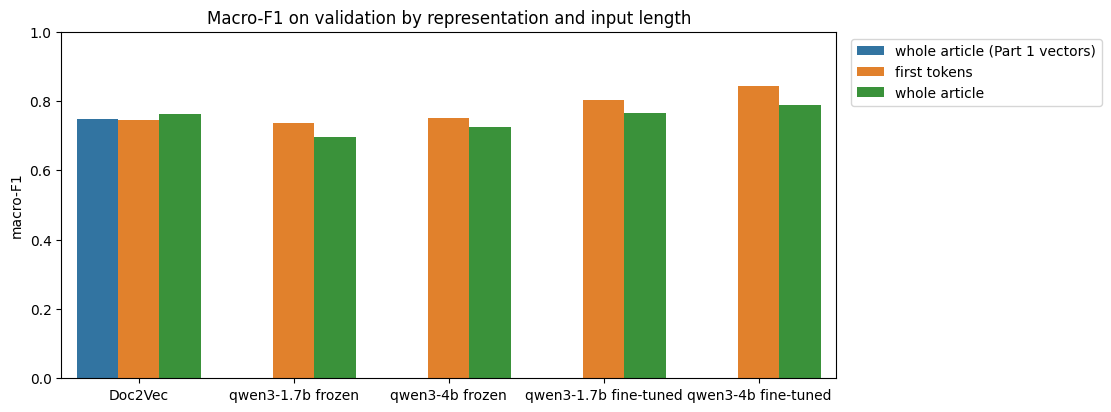

In [ ]:
# Representation x input
def describe(method):
    if method.startswith("Doc2Vec"):
        rep = "Doc2Vec"
        inp = "first tokens" if "first" in method else "whole article"
        inp += " (Part 1 vectors)" if method == "Doc2Vec + LogReg" else ""
    else:
        model = method.split(" ")[0]
        rep = f"{model} {'frozen' if 'frozen' in method else 'fine-tuned'}"
        inp = "whole article" if "(whole)" in method else "first tokens"
    return rep, inp

length = pd.DataFrame(RESULTS).drop_duplicates("method", keep="last")
length[["representation", "input"]] = length["method"].apply(lambda m: pd.Series(describe(m)))
length.to_csv(RUN_DIR / "results_input_length.csv", index=False)
display(length.pivot_table(index="representation", columns="input", values="macro_f1").round(3))

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=length, x="representation", y="macro_f1", hue="input", ax=ax)
ax.set(title="Macro-F1 on validation by representation and input length", xlabel="", ylabel="macro-F1", ylim=(0, 1))
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
save_fig(fig, "input_length")

**Interpretation**: reading the whole article does not help. The fine-tuned models drop (Qwen3-4B 0.84 → 0.79, Qwen3-1.7B 0.80 → 0.77), the frozen models drop by 2 to 4 points, and Doc2Vec changes by less than 2 points. The main subject of a news article is stated in its title and lead; averaging the windows gives the later parts, which often digress, the same weight as the beginning. For this task, the first 512 tokens are enough.

Limitation: the reviewed labels were made from the beginning of the articles (600 characters by hand, 6,000 by the LLM), which can favour the first-tokens input. With the topic labels, which the topic model computed from all the words of an article, the whole article helped instead (Section 2.6.5).

### 2.6.5 First run with the topic labels
The first run of this notebook trained and evaluated every method on the topic labels. It is kept to show how much the conclusions depend on the labels. The table compares the models trained on the topic labels (`trained on silver`) and on the reviewed labels (`trained on checked`), each scored on the reviewed labels (`macro_f1`, with interval) and on the topic labels (`macro_f1_silver`). It needs one run with each value of `TRAIN_LABELS`; all caches are kept, so the second run only trains what depends on the labels.

In [ ]:
runs = {version: OUT_DIR / ("" if version == "silver" else version) / "results_input_length.csv"
        for version in ["silver", "checked"]}
runs = {version: pd.read_csv(path, index_col="method") for version, path in runs.items() if path.exists()}
runs = {version: r for version, r in runs.items() if "macro_f1_silver" in r}   # results of the current notebook only

if len(runs) == 2:
    comparison = pd.concat({f"trained on {version}": r[["macro_f1", "f1_low", "f1_high", "macro_f1_silver"]]
                            for version, r in runs.items()}, axis=1)
    comparison[("gain", "macro_f1")] = (comparison[("trained on checked", "macro_f1")]
                                        - comparison[("trained on silver", "macro_f1")])
    comparison.to_csv(OUT_DIR / "results_label_versions.csv")
    display(comparison.round(3))
else:
    print("Run the notebook with TRAIN_LABELS =", " and ".join(f'"{v}"' for v in ["silver", "checked"] if v not in runs))

trained on silver                 \
                                            macro_f1 f1_low f1_high   
method                                                                
Doc2Vec + LogReg                               0.605  0.534   0.666   
qwen3-1.7b frozen + LogReg                     0.656  0.590   0.717   
qwen3-4b frozen + LogReg                       0.656  0.592   0.719   
qwen3-1.7b QLoRA                               0.635  0.568   0.693   
qwen3-4b QLoRA                                 0.659  0.593   0.720   
Doc2Vec (inferred, first) + LogReg             0.618  0.552   0.678   
Doc2Vec (inferred, whole) + LogReg             0.613  0.544   0.672   
qwen3-1.7b frozen (whole) + LogReg             0.614  0.550   0.673   
qwen3-1.7b fine-tuned (whole)                  0.655  0.586   0.719   
qwen3-4b frozen (whole) + LogReg               0.673  0.606   0.732   
qwen3-4b fine-tuned (whole)                    0.684  0.619   0.747   

                                                   trained on checked         \
                                   macro_f1_silver           macro_f1 f1_low   
method                                                                         
Doc2Vec + LogReg                             0.738              0.749  0.683   
qwen3-1.7b frozen + LogReg                   0.611              0.738  0.677   
qwen3-4b frozen + LogReg                     0.607              0.752  0.691   
qwen3-1.7b QLoRA                             0.693              0.804  0.746   
qwen3-4b QLoRA                               0.678              0.843  0.786   
Doc2Vec (inferred, first) + LogReg           0.658              0.745  0.681   
Doc2Vec (inferred, whole) + LogReg           0.718              0.762  0.696   
qwen3-1.7b frozen (whole) + LogReg           0.575              0.696  0.632   
qwen3-1.7b fine-tuned (whole)                0.717              0.765  0.700   
qwen3-4b frozen (whole) + LogReg             0.640              0.727  0.665   
qwen3-4b fine-tuned (whole)                  0.711              0.789  0.729   

                                                               gain  
                                   f1_high macro_f1_silver macro_f1  
method                                                               
Doc2Vec + LogReg                     0.805           0.540    0.144  
qwen3-1.7b frozen + LogReg           0.792           0.527    0.082  
qwen3-4b frozen + LogReg             0.805           0.535    0.096  
qwen3-1.7b QLoRA                     0.855           0.544    0.169  
qwen3-4b QLoRA                       0.891           0.536    0.183  
Doc2Vec (inferred, first) + LogReg   0.803           0.540    0.127  
Doc2Vec (inferred, whole) + LogReg   0.820           0.520    0.149  
qwen3-1.7b frozen (whole) + LogReg   0.754           0.548    0.081  
qwen3-1.7b fine-tuned (whole)        0.821           0.539    0.110  
qwen3-4b frozen (whole) + LogReg     0.785           0.549    0.054  
qwen3-4b fine-tuned (whole)          0.844           0.562    0.105

**Interpretation**: the conclusions of this part need the reviewed labels.
- Trained and scored on the topic labels, Doc2Vec ranked first (0.74), ahead of QLoRA (0.68 – 0.69) and the frozen models (0.61): the topic labels reward the representation closest to the topic model that made them, as both are built on word counts. Scored on the reviewed labels, the same Doc2Vec model comes last (0.61).
- Trained on the reviewed labels, every method improves, the fine-tuned models most (+17 and +18 points); only then does the gain of fine-tuning become visible.
- The effect of the input length also reverses: with the topic labels, the whole article helped (QLoRA Qwen3-1.7B 0.69 → 0.72, scored on the topic labels).

## 2.7 Article Vectors for the Comparative Evaluation
Part 3 compares all representations on the same intrinsic tasks (semantic similarity, clustering quality, visualisation). The article vectors of the compact models are therefore saved **in the same format as `doc_vectors.parquet` of Part 1** (`doc_id`, `split`, `om_tier`, `track`, `vector`), for two versions of each model: the frozen pre-trained model (`base`) and the fine-tuned model (`ft`).

The vectors are computed for the **same articles as the t-SNE map of Part 1** (all open-models articles and the same random sample of 4,000 other articles, same seed), so the maps of the classical and the compact models can be compared one to one. Embedding all 45,462 articles would take several hours on a T4.

In [ ]:
# Same sample as Part 1 (Section 1.3.2)
rng = np.random.default_rng(SEED)
track_idx = np.flatnonzero(doc_vectors["track"].to_numpy())
none_idx = np.flatnonzero(~doc_vectors["track"].to_numpy())
sample_idx = np.concatenate([track_idx, rng.choice(none_idx, size=min(len(none_idx), 4000), replace=False)])
vec_docs = doc_vectors.iloc[sample_idx][["doc_id", "split", "om_tier", "track"]].reset_index(drop=True)

titles = dict(zip(core["doc_id"], core["title"]))   # titles exist for core articles only
vec_docs = vec_docs.merge(corpus[["doc_id", "text"]], on="doc_id")
vec_docs["title"] = vec_docs["doc_id"].map(titles)
print(f"{len(vec_docs):,} articles to embed")

8,037 articles to embed


In [ ]:
def save_vectors(name, tag, E):
    vec_docs[["doc_id", "split", "om_tier", "track"]].assign(vector=list(E)).to_parquet(
        (OUT_DIR if tag == "base" else RUN_DIR) / f"llm_doc_vectors_{name}_{tag}.parquet", index=False)

for name, repo in MODELS.items():
    tok = load_tokenizer(repo)
    if not (OUT_DIR / f"llm_doc_vectors_{name}_base.parquet").exists():
        base = AutoModel.from_pretrained(repo, quantization_config=BNB, device_map="auto")
        save_vectors(name, "base", embed_cached(name, base, tok, vec_docs, "base_sample"))
        del base; free_memory()
    if not (RUN_DIR / f"llm_doc_vectors_{name}_ft.parquet").exists():
        ft, tok = finetune(name, repo)
        save_vectors(name, "ft", embed_cached(name, ft, tok, vec_docs, "ft_sample"))
        del ft; free_memory()

## 2.8 Open-Models Track: Unseen Model Names and Theme Trends
### 2.8.1 Unseen model names
Part 1 showed that Word2Vec has no vector for model names that never appeared in training, and that FastText gives them one from their character n-grams, so that its neighbours follow the spelling. The invented names of Part 1 (`qwen999-max`, `llama-999`, `deepseek-r999`) contain the name of their family: a model that splits words into sub-words will find the family from the spelling alone. They are kept for the comparison with Part 1, but they cannot show whether a model places a new name by its **meaning**.

The test therefore asks whether the compact model links an unseen name to its family **from the context**. Each name is placed in a sentence whose beginning names a company, and the vector of the **name tokens only** is compared with the vectors of five known family names:

| condition | example | expected nearest family |
|---|---|---|
| spelling | "A company has released its newest open-weight language model, qwen999-max." | the family in the name (Qwen) |
| context | "Meta has released its newest open-weight language model, Velora-7B." | the family of the company (Llama) |
| conflict | "Meta has released its newest open-weight language model, qwen999-max." | context (Llama) or spelling (Qwen)? |
| control | "A company has released its newest open-weight language model, Velora-7B." | no family: about 20% per family |

The company comes before the name because the model reads from left to right: the vector of a token depends only on the tokens before it. The family names are embedded in the neutral sentence, so that their vectors reflect what the model knows about them. All vectors are centred before the cosine similarity, because the vectors of a language model share a common direction that makes every similarity high. FastText, which does not read the context, follows the spelling in every conflict sentence by construction.

In [ ]:
FAMILIES = ["Qwen", "Llama", "DeepSeek", "Gemma", "Nemotron"]
COMPANY = {"Qwen": "Alibaba Cloud", "Llama": "Meta", "DeepSeek": "The Chinese lab behind the R1 reasoning model",
           "Gemma": "Google DeepMind", "Nemotron": "NVIDIA"}
NEUTRAL = "A company"
FRAME = "{} has released its newest open-weight language model, {}."   # company first: the model reads left to right
SPELLED = {"qwen999-max": "Qwen", "llama-999": "Llama", "deepseek-r999": "DeepSeek"}   # invented names of Part 1
INVENTED = ["Velora-7B", "Kestrix-2", "Orvane-9B", "Tamsin-3", "Brivo-14B"]          # no family in the name

rows = []
for word in INVENTED:
    rows += [("control", word, None, None)] + [("context", word, f, None) for f in FAMILIES]
for word, family in SPELLED.items():
    rows += [("spelling", word, None, family)] + [("conflict", word, f, family) for f in FAMILIES if f != family]
tests = pd.DataFrame(rows, columns=["condition", "name", "context_family", "spelling_family"])
tests["sentence"] = [FRAME.format(COMPANY[f] if f else NEUTRAL, w) for w, f in zip(tests["name"], tests["context_family"])]

@torch.no_grad()
def name_vectors(model, tok, sentences, names):
    """Mean of the last hidden states of the tokens of the name, not of the whole sentence."""
    model.eval()
    out = []
    for sentence, word in zip(sentences, names):
        enc = tok(sentence, return_offsets_mapping=True, return_tensors="pt")
        start = sentence.rindex(word)
        in_name = torch.tensor([a < start + len(word) and b > start for a, b in enc.pop("offset_mapping")[0].tolist()])
        hidden = model(**enc.to("cuda"), output_hidden_states=True).hidden_states[-1][0]
        out.append(hidden[in_name.to(hidden.device)].float().mean(0).cpu().numpy())
    return np.vstack(out)

def nearest_family(model, tok):
    V = name_vectors(model, tok, list(tests["sentence"]) + [FRAME.format(NEUTRAL, f) for f in FAMILIES],
                     list(tests["name"]) + FAMILIES)
    V = unit(V - V.mean(0))   # centre: remove the direction shared by all vectors
    return np.array(FAMILIES)[(V[:len(tests)] @ V[len(tests):].T).argmax(1)]

name, repo = next(iter(MODELS.items()))   # main model
tok = load_tokenizer(repo)
for word in list(SPELLED) + INVENTED:
    print(f"{word:15} -> {tok.tokenize(' ' + word)}")

base = AutoModel.from_pretrained(repo, quantization_config=BNB, device_map="auto")
tests["frozen"] = nearest_family(base, tok)
del base; free_memory()
ft, tok = finetune(name, repo)
tests["fine-tuned"] = nearest_family(ft, tok)
del ft; free_memory()
tests.to_csv(RUN_DIR / "unseen_names.csv", index=False)

def share(condition, target):
    d = tests[tests["condition"] == condition]
    return {"sentences": len(d), **{m: (d[m] == d[target]).mean() for m in ["frozen", "fine-tuned"]}}

display(pd.DataFrame({"spelling: nearest = family in the name": share("spelling", "spelling_family"),
                      "context: nearest = family of the company": share("context", "context_family"),
                      "conflict: follows the company": share("conflict", "context_family"),
                      "conflict: follows the spelling": share("conflict", "spelling_family")}).T.round(2))
print("Control sentences (no family), nearest family:")
display(tests[tests["condition"] == "control"].set_index("name")[["frozen", "fine-tuned"]])

**Interpretation**: the compact model places unseen names by their **spelling, not by their context**.
- **Spelling**: the three names of Part 1 are all closest to the family in their name, for the frozen and the fine-tuned model. As with FastText, the sub-words (`q` + `wen`, `llama`, `deep` + `seek`) are enough.
- **Context**: without a family in the name, the company before it does not lead to the right family: 20% of the sentences for the frozen model, the rate of chance with five families, and 32% for the fine-tuned model (8 of 25, p = 0.11 against chance). The control sentences show why this small gain is not evidence of context use: without any company, the fine-tuned model places 4 of the 5 invented names next to Qwen, so a part of its correct answers can come from this preference.
- **Conflict**: when the spelling and the company disagree, both models follow the spelling in all 12 sentences, as FastText does by construction.

The compact models therefore solve the problem of Word2Vec (every name gets a vector), but for names, they behave like FastText rather than like a reader who links a new model to its developer. Fine-tuning on theme classification does not change this, which is expected: the task does not require knowing the family of a model. Limitations: one sentence frame, five families and the last layer only; the vector of a token in a left-to-right model also encodes the prediction of the next token.

### 2.8.2 Theme trends beyond the labelled articles
Only the core articles have a Stage 1 topic. The fine-tuned classifier can label the **mention** articles too (2,827 articles that name open models without being centred on them), which extends the theme trends of the track to a larger part of the corpus. The predictions are saved for the insight extraction in Part 3.

As the classifier was trained on core articles, its predictions on mention articles are less reliable: the predicted probability is kept so that Part 3 can filter on confidence.

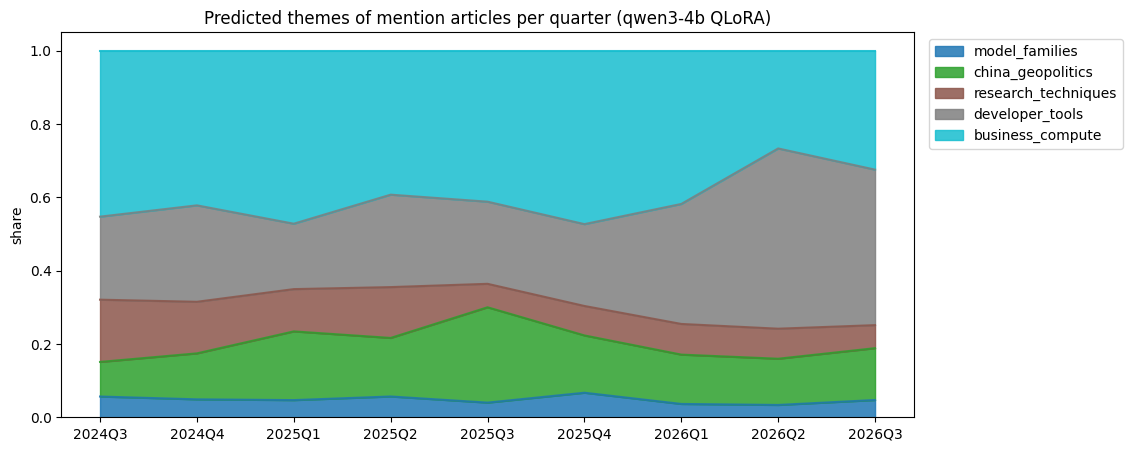

In [ ]:
best_name = results.filter(like="QLoRA", axis=0)["macro_f1"].idxmax().replace(" QLoRA", "")
PRED_PATH = RUN_DIR / f"predictions_track_{best_name}.parquet"   # one file per model, so a new best model is not read from an old cache

if PRED_PATH.exists():
    preds = pd.read_parquet(PRED_PATH)
else:
    track_docs = corpus[corpus["om_tier"].isin(["core", "mention", "reference"])][["doc_id", "quarter", "om_tier", "split", "text"]]
    track_docs = track_docs.assign(title=track_docs["doc_id"].map(titles))
    ft, tok = finetune(best_name, MODELS[best_name])
    with track(best_name, "predict_track"):
        P = predict_proba(ft, tok, model_input(track_docs))
    del ft; free_memory()
    preds = track_docs.drop(columns=["text", "title"]).assign(model=best_name, pred=[LABELS[i] for i in P.argmax(1)],
                                                             confidence=P.max(1))
    preds = preds.join(pd.DataFrame(P, columns=[f"p_{l}" for l in LABELS], index=preds.index))
    preds.to_parquet(PRED_PATH, index=False)

share = (preds[preds["om_tier"] == "mention"].groupby("quarter")["pred"].value_counts(normalize=True)
         .unstack(fill_value=0).reindex(columns=LABELS, fill_value=0))
fig, ax = plt.subplots(figsize=(11, 5))
share.plot.area(ax=ax, cmap="tab10", alpha=0.85)
ax.set(title=f"Predicted themes of mention articles per quarter ({best_name} QLoRA)", xlabel="", ylabel="share")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
save_fig(fig, "theme_share_mention")

**Interpretation** (shares read from the figure; the classifier was trained on core articles, so the predictions on mention articles are less reliable):
- `developer_tools` grows the most: from about 23% of the mention articles in 2024Q3 to about 49% in 2026Q2 (42% in 2026Q3). Open models are increasingly mentioned as building blocks of agents, coding tools and platforms.
- `business_compute` is the largest theme until 2025Q4 (about 40–47%) and falls to about 27–33% in 2026.
- `research_techniques` shrinks from about 17% to 6–9%, and `china_geopolitics` peaks in 2025Q3 (about 26%).
- `model_families` stays small (4–7%), as expected: mention articles name open models without being about them.

Part 3 can restrict these trends to confident predictions (`confidence` column) and compare them with the topic trends of Stage 1.

## 2.9 Outputs and Handover to Part 3
All outputs are saved on Google Drive. The outputs that depend on the training labels are in `RUN_DIR`: `OUT_DIR/checked` for the reviewed labels, `OUT_DIR` for the first run on the topic labels.

| file | content |
|---|---|
| `task_labels.parquet` | articles of the task with Stage 1 topic, topic label, reviewed label, label source and set (train / dev / validation) |
| `results_validation.csv` | macro-F1 of every method on the shared validation split (reviewed labels with bootstrap interval, and topic labels) |
| `results_robustness.csv`, `results_paired.csv` | scores on the hand-checked labels and paired bootstrap differences (Section 2.6.3) |
| `results_input_length.csv` | the same for every representation and input length (Section 2.6.4) |
| `results_label_versions.csv` (`OUT_DIR`) | first run on the topic labels vs reviewed labels (Section 2.6.5) |
| `resources.json` | per model: time and peak GPU memory of every step, parameters, trainable share, adapter size, settings |
| `train_log_<model>.csv` | training and dev metrics per step / epoch |
| `adapters/<model>/` | LoRA adapters and classification head |
| `llm_doc_vectors_<model>_{base,ft}.parquet` | article vectors, same format and same articles as the t-SNE map of Part 1 |
| `unseen_names.csv` | test of unseen model names (Section 2.8.1) |
| `predictions_track_<model>.parquet` | theme probabilities of all open-models articles (best fine-tuned model) |
| `label_check_validation.csv` (`OUT_DIR`) | hand check of the topic labels (Section 2.2.2) |
| `figures/` | visualisations |

The times depend on the GPU each step ran on (`train_gpu`, `val_predict_gpu`): they are compared between models only when the GPU is the same.

In [ ]:
# Trade-off summary for Part 3
rows = []
for name in MODELS:
    r = RESOURCES.get(name, {})
    rows.append({"model": name, "total_params_M": r.get("total_params", np.nan) / 1e6,
                 "trainable_pct": r.get("trainable_pct"), "adapter_mb": r.get("adapter_mb"),
                 "train_gpu": r.get("finetune", {}).get("gpu"),
                 "train_min": r.get("finetune", {}).get("seconds", np.nan) / 60,
                 "train_peak_vram_gb": r.get("finetune", {}).get("peak_vram_gb"),
                 "val_predict_gpu": r.get("predict_validation", {}).get("gpu"),
                 "val_predict_s": r.get("predict_validation", {}).get("seconds"),
                 "val_macro_f1": results["macro_f1"].get(f"{name} QLoRA")})
display(pd.DataFrame(rows).round(2))

,model,total_params_M,trainable_pct,adapter_mb,train_gpu,train_min,train_peak_vram_gb,val_predict_gpu,val_predict_s,val_macro_f1
0,qwen3-1.7b,1727.02,0.37,24.6,NVIDIA L4,9.01,2.82,NVIDIA L4,14.0,0.80
1,qwen3-4b,4034.29,0.29,45.1,NVIDIA L4,21.16,4.80,NVIDIA L4,28.5,0.84


### AI Disclosure
Claude Code (Claude Opus 5.5) was used in two roles in this work package.

**1. Coding and writing assistant.** It supported debugging the notebook code, reducing the processing time, the statistical checks.

**2. Annotator of the reviewed labels (Section 2.2.3).** It assigned theme labels to 1,060 articles using a predefined rubric, without access to the topic labels. These labels were used for training. Validation labels were manually checked (100 independently, 68 with LLM labels visible; κ = 0.70). Potential LLM-related evaluation bias is discussed in Section 2.6.3.

The task design, the choice of the methods, the hand check of the labels and the final decisions were made by the author of this work package, who reviewed all code, results and text.